In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using MLJ
using Dates
using JuMP, Ipopt
using LinearAlgebra

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

Number of groups: 7300
Training groups: 5840
Validation groups: 730
Testing groups: 730
Power RBF centers: 21
Time RBF centers: 24
Total RBF features: 45

Best hyperparameters:
γ_power = 10.0
γ_hour = 1.0
λ = 0.01
Best validation RMSE = 0.19489472965627497

Final training performance:
Training RMSE = 0.037487676593950886
Training MAE = 0.028445246463380616

Final validation performance:
Validation RMSE = 0.19515724597467282
Validation MAE = 0.13995655353989117

Final testing performance:
Test RMSE = 0.19688012919669134
Test MAE = 0.14307128930888774
Actual power range = (0.0, 0.9817)
Predicted power range = (0.013526620345873208, 0.9225204946686962)

Test predictions saved.


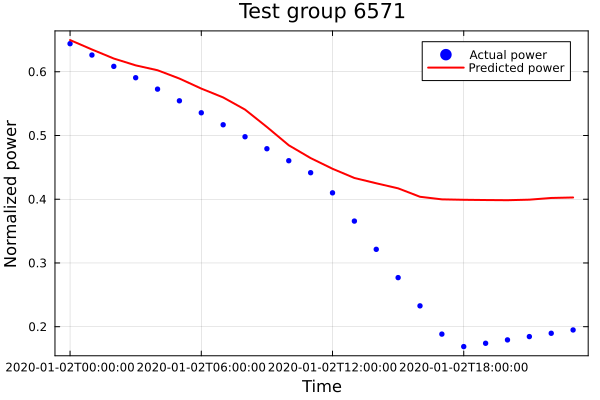

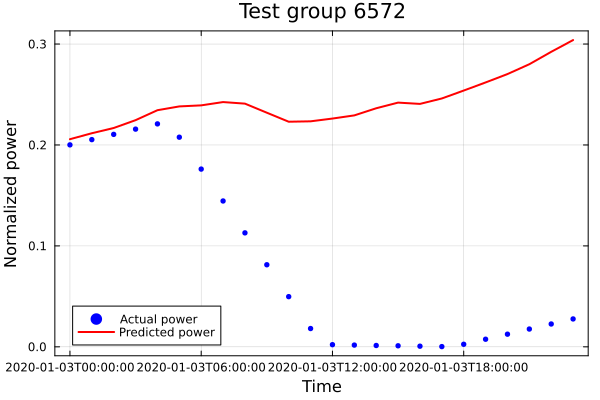

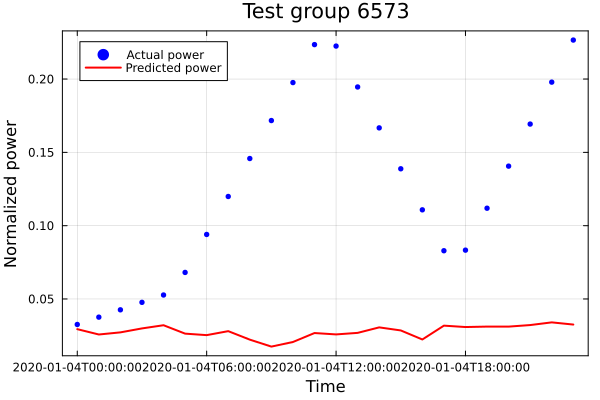

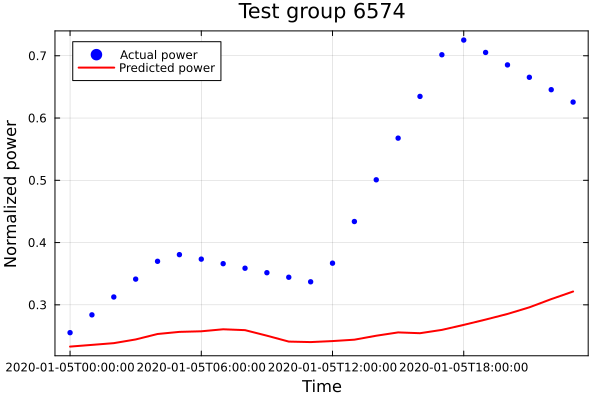

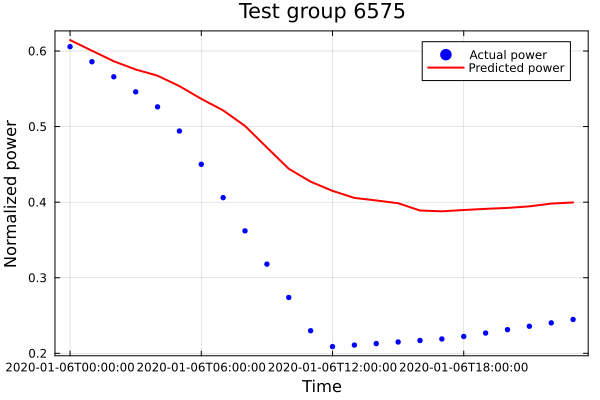

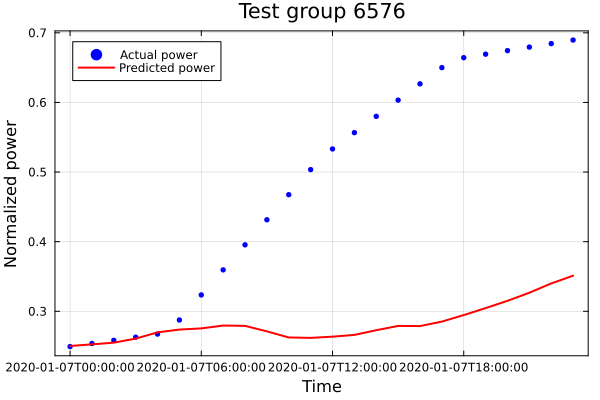

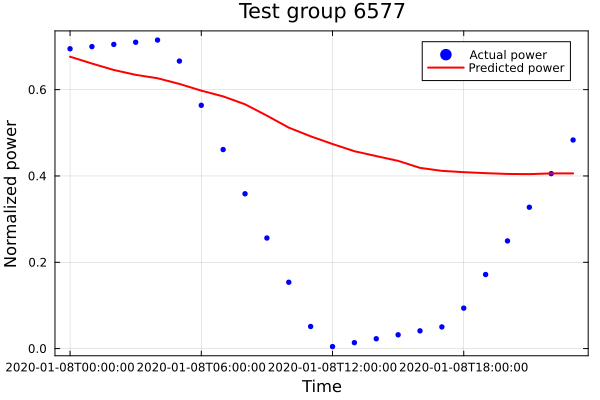

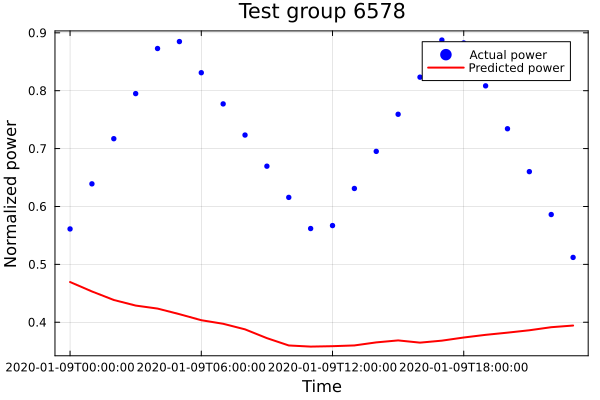

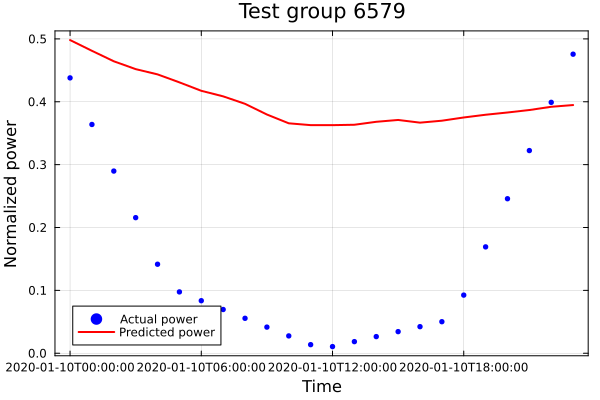

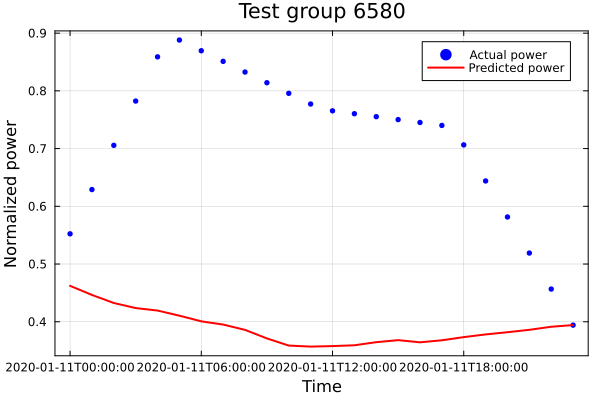

In [ ]:

using CSV, DataFrames, Dates, Random, Statistics, LinearAlgebra, Plots

# ============================================================
# 1. LOAD AND COMBINE ALL FOUR LOCATIONS
# ============================================================

dfs = [CSV.read("location$i.csv", DataFrame; types=Dict(:Time => String)) for i in 1:4]

for (i, data) in enumerate(dfs)
    data.Time = DateTime.(data.Time, dateformat"yyyy-mm-dd HH:MM:SS")
    data.LocationID = fill(i, nrow(data))
end

df = vcat(dfs...)
sort!(df, [:LocationID, :Time])

t = Float64.(df.Power)
times = df.Time
location_ids = df.LocationID
m = length(t)

# ============================================================
# 2. CREATE 24-OBSERVATION GROUPS
# ============================================================

hours_per_group = 24
num_groups = div(m, hours_per_group)
m_used = num_groups * hours_per_group

t, times, location_ids = t[1:m_used], times[1:m_used], location_ids[1:m_used]

groups = [collect(((i-1)*hours_per_group+1):(i*hours_per_group)) for i in 1:num_groups]

# ============================================================
# 3. PREVIOUS-DAY, LAST-HOUR LOOKUP
# ============================================================

prev_day_idx = zeros(Int, m_used)

for i in 1:m_used
    if Dates.hour(times[i]) == 0 && Dates.minute(times[i]) == 0
        previous_day_time = times[i] - Day(1) + Hour(23)
        match = findfirst(j -> location_ids[j] == location_ids[i] && times[j] == previous_day_time, 1:m_used)
        if match !== nothing
            prev_day_idx[i] = match
        end
    end
end

# Find the actual preceding-hour observation for every row.
# At midnight, use the previous day's 23:00 observation.
lag_idx = [
    prev_day_idx[i] > 0 ? prev_day_idx[i] :
    (i > 1 && location_ids[i] == location_ids[i-1] && times[i] - times[i-1] == Hour(1) ? i-1 : 0)
    for i in 1:m_used
]

# ============================================================
# 4. TRAIN / VALIDATION / TEST PARTITION
# ============================================================

n_train = floor(Int, 0.8 * num_groups)
n_val = floor(Int, 0.1 * num_groups)

train_groups = collect(1:n_train)
val_groups = collect((n_train+1):(n_train+n_val))
test_groups = collect((n_train+n_val+1):num_groups)

train_idx = reduce(vcat, groups[train_groups])
val_idx = reduce(vcat, groups[val_groups])
test_idx = reduce(vcat, groups[test_groups])

println("Number of groups: ", num_groups)
println("Training groups: ", length(train_groups))
println("Validation groups: ", length(val_groups))
println("Testing groups: ", length(test_groups))

# ============================================================
# 5. EXTRACT TIME FEATURES
# ============================================================

hour = Float64.([Dates.hour(time) + Dates.minute(time)/60 for time in times])

# ============================================================
# 6. DEFINE RBF CENTERS
# ============================================================

c_power = collect(0.0:0.05:1.0)
c_hour = collect(0.0:1.0:23.0)

num_power_centers = length(c_power)
num_hour_centers = length(c_hour)

println("Power RBF centers: ", num_power_centers)
println("Time RBF centers: ", num_hour_centers)
println("Total RBF features: ", num_power_centers + num_hour_centers)

# ============================================================
# 7. RBF FEATURE TRANSFORMATION
# ============================================================

function rbf_features(power, hour, γ_power, γ_hour, c_power, c_hour)
    Φ_power = [exp(-(γ_power * abs(p-c))^2) for p in power, c in c_power]
    Φ_hour = [exp(-(γ_hour * min(abs(h-c), 24-abs(h-c)))^2) for h in hour, c in c_hour]
    return hcat(Φ_power, Φ_hour)
end

# ============================================================
# 8. SGD TRAINING FUNCTION
# ============================================================

function train_rbf(Φ, Y; α=0.02, n_epochs=20, λ=0.001, reg_type=:l2, seed=128)
    n, p = size(Φ)
    rng = MersenneTwister(seed)
    w_0, w = 0.0, zeros(p)

    for epoch in 1:n_epochs
        for i in randperm(rng, n)
            residual = w_0 + dot(Φ[i,:], w) - Y[i]
            w_0 -= α * residual

            if reg_type == :l2
                w .-= α .* (residual .* Φ[i,:] .+ λ .* w)
            elseif reg_type == :l1
                w .-= α .* residual .* Φ[i,:]
                w .= sign.(w) .* max.(0.0, abs.(w) .- α*λ)
            else
                error("Unknown regularization type")
            end
        end
    end

    return w_0, w
end

# ============================================================
# 9. PREDICTION AND ERROR FUNCTIONS
# ============================================================

predict_rbf(Φ, w_0, w) = w_0 .+ Φ*w
rmse(actual, predicted) = sqrt(mean((actual .- predicted).^2))
mae(actual, predicted) = mean(abs.(actual .- predicted))

# ============================================================
# 10. RECURSIVE PREDICTION WITH DAILY RESET
# ============================================================

function predict_recursive(indices, w_0, w, γ_power, γ_hour, hour, times, location_ids, prev_day_idx, c_power, c_hour, actual_power)
    predictions = zeros(length(indices))
    index_position = Dict(idx => j for (j, idx) in enumerate(indices))

    for j in eachindex(indices)
        i = indices[j]

        if Dates.hour(times[i]) == 0 && Dates.minute(times[i]) == 0
            prev_day_idx[i] > 0 || error("Previous-day 23:00 power unavailable for observation $i")
            previous_power = actual_power[prev_day_idx[i]]
        else
            previous_idx = i - 1

            if haskey(index_position, previous_idx) && location_ids[previous_idx] == location_ids[i] && times[i] - times[previous_idx] == Hour(1)
                previous_power = predictions[index_position[previous_idx]]
            elseif i > 1 && location_ids[i] == location_ids[i-1] && times[i] - times[i-1] == Hour(1)
                previous_power = actual_power[i-1]
            else
                error("Previous-hour power unavailable for observation $i")
            end
        end

        Φ = rbf_features([previous_power], [hour[i]], γ_power, γ_hour, c_power, c_hour)
        predictions[j] = clamp(w_0 + dot(Φ[1,:], w), 0.0, 1.0)
    end

    return predictions
end

# ============================================================
# 11. HYPERPARAMETER SEARCH
# ============================================================

γ_power_grid = [0.5, 1.0, 2.0, 5.0, 10.0]
γ_hour_grid = [0.05, 0.1, 0.2, 0.5, 1.0]
λ_grid = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]

train_idx_fit = filter(i -> lag_idx[i] > 0, train_idx)
lag_train = t[lag_idx[train_idx_fit]]
Y_train = t[train_idx_fit]

best_validation_rmse = Inf
best_γ_power, best_γ_hour, best_λ = NaN, NaN, NaN
best_w_0, best_w = 0.0, Float64[]


for γ_power in γ_power_grid, γ_hour in γ_hour_grid
    Φ_train = rbf_features(lag_train, hour[train_idx_fit], γ_power, γ_hour, c_power, c_hour)

    for λ in λ_grid
        w_0, w = train_rbf(Φ_train, Y_train; α=0.02, n_epochs=20, λ=λ, reg_type=:l2, seed=128)

        Y_val_pred = predict_recursive(val_idx, w_0, w, γ_power, γ_hour, hour, times, location_ids, prev_day_idx, c_power, c_hour, t)
        validation_rmse = rmse(t[val_idx], Y_val_pred)

        if validation_rmse < best_validation_rmse
            best_validation_rmse = validation_rmse
            best_γ_power, best_γ_hour, best_λ = γ_power, γ_hour, λ
            best_w_0, best_w = w_0, copy(w)
        end
    end
end

println("\nBest hyperparameters:")
println("γ_power = ", best_γ_power)
println("γ_hour = ", best_γ_hour)
println("λ = ", best_λ)
println("Best validation RMSE = ", best_validation_rmse)

# ============================================================
# 12. RETRAIN USING TRAINING + VALIDATION DATA
# ============================================================

train_val_idx = vcat(train_idx, val_idx)
train_val_idx_fit = filter(i -> lag_idx[i] > 0, train_val_idx)

lag_train_val = t[lag_idx[train_val_idx_fit]]
Y_train_val = t[train_val_idx_fit]

Φ_train_val = rbf_features(lag_train_val, hour[train_val_idx_fit], best_γ_power, best_γ_hour, c_power, c_hour)

w_0_final, w_final = train_rbf(Φ_train_val, Y_train_val; α=0.02, n_epochs=20, λ=best_λ, reg_type=:l2, seed=128)

# ============================================================
# 13. FINAL TRAINING PERFORMANCE
# ============================================================

Y_train_val_fitted = clamp.(predict_rbf(Φ_train_val, w_0_final, w_final), 0.0, 1.0)

println("\nFinal training performance:")
println("Training RMSE = ", rmse(Y_train_val, Y_train_val_fitted))
println("Training MAE = ", mae(Y_train_val, Y_train_val_fitted))

# ============================================================
# 14. VALIDATION PREDICTIONS
# ============================================================

Y_val_pred = predict_recursive(val_idx, w_0_final, w_final, best_γ_power, best_γ_hour, hour, times, location_ids, prev_day_idx, c_power, c_hour, t)

println("\nFinal validation performance:")
println("Validation RMSE = ", rmse(t[val_idx], Y_val_pred))
println("Validation MAE = ", mae(t[val_idx], Y_val_pred))

# ============================================================
# 15. TEST PREDICTIONS
# ============================================================

Y_test_pred = predict_recursive(test_idx, w_0_final, w_final, best_γ_power, best_γ_hour, hour, times, location_ids, prev_day_idx, c_power, c_hour, t)

println("\nFinal testing performance:")
println("Test RMSE = ", rmse(t[test_idx], Y_test_pred))
println("Test MAE = ", mae(t[test_idx], Y_test_pred))
println("Actual power range = ", extrema(t[test_idx]))
println("Predicted power range = ", extrema(Y_test_pred))

# ============================================================
# 16. PLOT TEST GROUPS
# ============================================================

test_position = Dict(idx => j for (j, idx) in enumerate(test_idx))

for group_num in test_groups[1:min(10, length(test_groups))]
    idx = groups[group_num]
    group_predictions = [Y_test_pred[test_position[i]] for i in idx]

    p = scatter(times[idx], t[idx]; color=:blue, label="Actual power", markersize=3, markerstrokewidth=0, frame=:box, xlabel="Time", ylabel="Normalized power", title="Test group $group_num", legend=:best)
    plot!(p, times[idx], group_predictions; color=:red, linewidth=2, label="Predicted power")
    display(p)
end

